# 5.48

## a)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize


def backward_euler(f, x0, t0, tmax, dt):
    """Implicit Euler: solve x_{n+1} = x_n + dt f(t_{n+1}, x_{n+1}) each step."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        equation = lambda y: y - x[n] - dt * f(t[n + 1], y)
        x[n + 1] = optimize.fsolve(equation, x[n])[0]
    return t, x


def euler(f, x0, t0, tmax, dt):
    """Explicit Euler, for comparison."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        x[n + 1] = x[n] + dt * f(t[n], x[n])
    return t, x


f = lambda t, x: -0.5 * x
t, x_backward = backward_euler(f, 6, 0, 10, 1)
_, x_euler = euler(f, 6, 0, 10, 1)
exact = 6 * np.exp(-0.5 * t)

table = pd.DataFrame({"t": t, "backward Euler": x_backward,
                      "Euler": x_euler, "exact": exact})
print(table.round(5).to_string(index=False))


 t  backward Euler   Euler   exact
 0         6.00000 6.00000 6.00000
 1         4.00000 3.00000 3.63918
 2         2.66667 1.50000 2.20728
 3         1.77778 0.75000 1.33878
 4         1.18519 0.37500 0.81201
 5         0.79012 0.18750 0.49251
 6         0.52675 0.09375 0.29872
 7         0.35117 0.04688 0.18118
 8         0.23411 0.02344 0.10989
 9         0.15607 0.01172 0.06665
10         0.10405 0.00586 0.04043


## b)

In [2]:
def midpoint(f, x0, t0, tmax, dt):
    """Second-order Runge-Kutta (midpoint) method."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        half = x[n] + 0.5 * dt * f(t[n], x[n])
        x[n + 1] = x[n] + dt * f(t[n] + 0.5 * dt, half)
    return t, x


t, x_midpoint = midpoint(f, 6, 0, 10, 1)
table["midpoint"] = x_midpoint
print(table.round(5).to_string(index=False))


 t  backward Euler   Euler   exact  midpoint
 0         6.00000 6.00000 6.00000   6.00000
 1         4.00000 3.00000 3.63918   3.75000
 2         2.66667 1.50000 2.20728   2.34375
 3         1.77778 0.75000 1.33878   1.46484
 4         1.18519 0.37500 0.81201   0.91553
 5         0.79012 0.18750 0.49251   0.57220
 6         0.52675 0.09375 0.29872   0.35763
 7         0.35117 0.04688 0.18118   0.22352
 8         0.23411 0.02344 0.10989   0.13970
 9         0.15607 0.01172 0.06665   0.08731
10         0.10405 0.00586 0.04043   0.05457


# 5.50

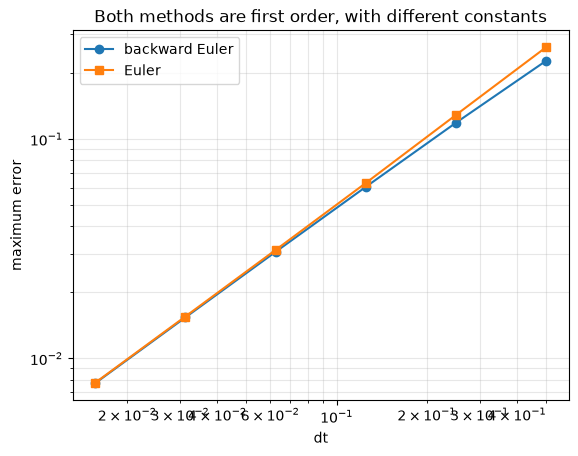

In [3]:
f = lambda t, x: -(1 / 3.0) * x + np.sin(t)
exact = lambda t: (1 / 10.0) * (19 * np.exp(-t / 3) + 3 * np.sin(t) - 9 * np.cos(t))

dt_list = 0.5 ** np.arange(1, 7)
errors_backward, errors_euler = [], []
for dt in dt_list:
    t_b, x_b = backward_euler(f, 1, 0, 10, dt)
    t_e, x_e = euler(f, 1, 0, 10, dt)
    errors_backward.append(np.max(np.abs(x_b - exact(t_b))))
    errors_euler.append(np.max(np.abs(x_e - exact(t_e))))

plt.figure()
plt.loglog(dt_list, errors_backward, "o-", label="backward Euler")
plt.loglog(dt_list, errors_euler, "s-", label="Euler")
plt.xlabel("dt")
plt.ylabel("maximum error")
plt.title("Both methods are first order, with different constants")
plt.grid(which="both", alpha=0.3)
plt.legend()
plt.show()


Find the rate of convergence for backwards euler + make a log-log plot comparing it to other methods.
